<a href="https://colab.research.google.com/github/marianagomez3108-spec/Facturacion/blob/main/Quiz3_SerieTiempo_TickerAsignado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quiz 3 · Análisis de una serie de tiempo financiera

**Estudiante:** Mariana Guisao Gómez
**Ticker asignado:** CVX
**Activo analizado:** CVX  
**Periodo de análisis:** 2024-01-01 a 2026-10-02

## Propósito
Analizar el comportamiento histórico de una serie de tiempo financiera mediante visualización, rendimientos, volatilidad y una proyección de corto plazo.

> Este análisis tiene fines académicos y no constituye una recomendación de inversión.

## 0. Configuración
Escriba su ticker exactamente como aparece en S22. No lo cambie: la entrega se revisa contra el ticker asignado.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

TICKER = "CVX"
FECHA_INICIO = "2024-01-01"
FECHA_FIN = "2026-10-01"

## 1. Contexto del activo
Indique qué activo representa el ticker, en qué mercado se negocia, su moneda y por qué es relevante analizarlo. Cite la fuente.

Chevron Corporation es una empresa estadounidense perteneciente al sector energético, dedicada a actividades relacionadas con la exploración, producción y comercialización de petróleo y gas natural. Sus acciones ordinarias se negocian en la Bolsa de Valores de Nueva York (NYSE) bajo el símbolo bursátil CVX y se cotizan en dólares estadounidenses (USD).

El análisis de esta acción es relevante porque su comportamiento puede verse afectado por las variaciones en los precios internacionales del petróleo, la demanda energética, los resultados financieros de la empresa y las condiciones económicas mundiales. Mediante el análisis de su serie de tiempo es posible estudiar la evolución de los precios, los rendimientos diarios y la volatilidad.

Fuente: "Chevron — información oficial sobre acciones y dividendos" (https://www.chevron.com/investors/stock-and-dividend).

## 2. Descarga de datos
Descargue al menos dos años de precios diarios.

In [ ]:
datos = yf.download(
    TICKER,
    start=FECHA_INICIO,
    end=FECHA_FIN,
    interval="1d",
    auto_adjust=True,
    progress=False
)

if datos.empty:
    raise ValueError("No se descargaron datos. Revisa el ticker o la conexión.")

cierre = datos["Close"]

if isinstance(cierre, pd.DataFrame):
    cierre = cierre[TICKER]

cierre = cierre.dropna().rename("Cierre")

display(datos.head())
display(datos.tail())

Price,Close,High,Low,Open,Volume
Ticker,CVX,CVX,CVX,CVX,CVX
Date,,,,,
2024-01-02,133.236725,135.019394,133.022813,133.691314,8879700
2024-01-03,135.777054,136.543602,132.523673,133.156527,10255300
2024-01-04,134.288528,137.577557,134.226128,136.962533,8220300
2024-01-05,134.056763,135.509643,133.548709,135.465073,7455400
2024-01-08,133.254547,133.432811,130.651851,132.291904,10038200


Price,Close,High,Low,Open,Volume
Ticker,CVX,CVX,CVX,CVX,CVX
Date,,,,,
2026-09-24,205.649994,208.100006,204.869995,207.240005,9382800
2026-09-25,204.449997,206.539993,203.399994,203.809998,7134300
2026-09-28,206.369995,208.250000,205.380005,207.000000,9529800
2026-09-29,204.380005,205.479996,202.699997,203.050003,5917600
2026-09-30,204.210007,206.830002,204.210007,205.089996,6390200


## 3. Calidad de datos
Revise periodo real, frecuencia, número de observaciones, valores faltantes y duplicados.

In [ ]:
print("Número de observaciones:", len(cierre))
print("Fecha inicial:", cierre.index.min())
print("Fecha final:", cierre.index.max())
print("Valores faltantes:", cierre.isna().sum())
print("Fechas duplicadas:", cierre.index.duplicated().sum())

Número de observaciones: 689
Fecha inicial: 2024-01-02 00:00:00
Fecha final: 2026-09-30 00:00:00
Valores faltantes: 0
Fechas duplicadas: 0


**Interpretación:** indique las decisiones de limpieza aplicadas.

los datos son diarios, pero solo de días bursátiles. Por eso no deben aparecer precios para todos los sábados, domingos y festivos.

## 4. Serie de precios
Grafique el precio de cierre en el tiempo, con título, ejes y fuente.

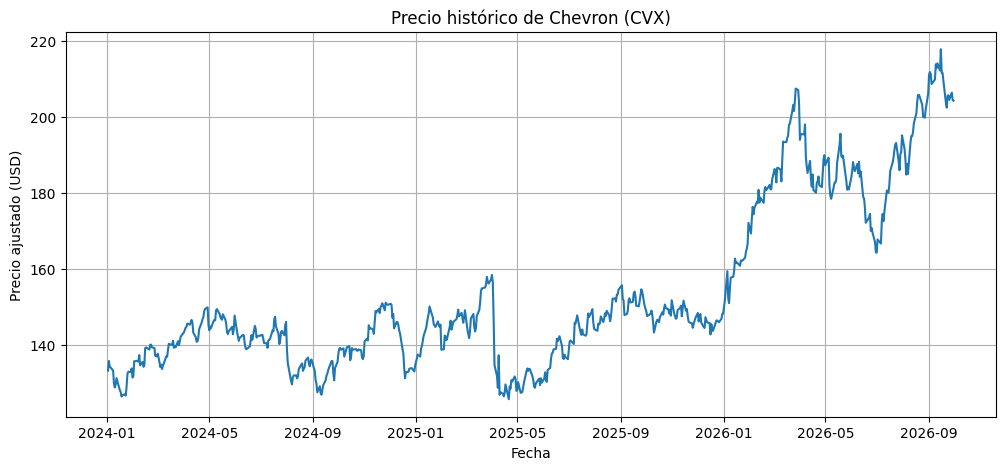

Precio mínimo: 125.71247100830078
Fecha del mínimo: 2025-04-21 00:00:00
Precio máximo: 217.77000427246094
Fecha del máximo: 2026-09-15 00:00:00


In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(cierre.index, cierre.values)
plt.title("Precio histórico de Chevron (CVX)")
plt.xlabel("Fecha")
plt.ylabel("Precio ajustado (USD)")
plt.grid(True)
plt.show()

print("Precio mínimo:", cierre.min())
print("Fecha del mínimo:", cierre.idxmin())
print("Precio máximo:", cierre.max())
print("Fecha del máximo:", cierre.idxmax())

## 5. Lectura temporal
Describa tendencia, máximos, mínimos y cambios relevantes que observa en el gráfico.

Análisis del precio histórico de CVX

Durante el periodo analizado, la acción de Chevron Corporation (CVX) registró un precio mínimo de US$125,71 el 21 de abril   2025 y un precio máximo de US$217,77 el 15 de septiembre de 2026. La diferencia entre ambos valores fue de US$92,06, lo que evidencia una variación considerable del precio de la acción durante el periodo estudiado.

Tomando el precio mínimo como referencia, el precio máximo fue aproximadamente un 73,19 % superior. Estos resultados muestran que la acción experimentó fluctuaciones importantes a lo largo del tiempo. Sin embargo, estos dos valores por sí solos no permiten concluir que el precio haya mantenido una tendencia ascendente constante, por lo que también es necesario observar la gráfica histórica.

## 6. Rendimientos diarios
Calcule los rendimientos diarios, presente su resumen estadístico y grafíquelos.

,Cierre
count,688.000000
mean,0.000726
std,0.014474
min,-0.082244
25%,-0.006616
50%,0.001454
75%,0.009243
max,0.066457


Rendimiento promedio (%): 0.07261345519284616
Desviación estándar (%): 1.4473862197057228


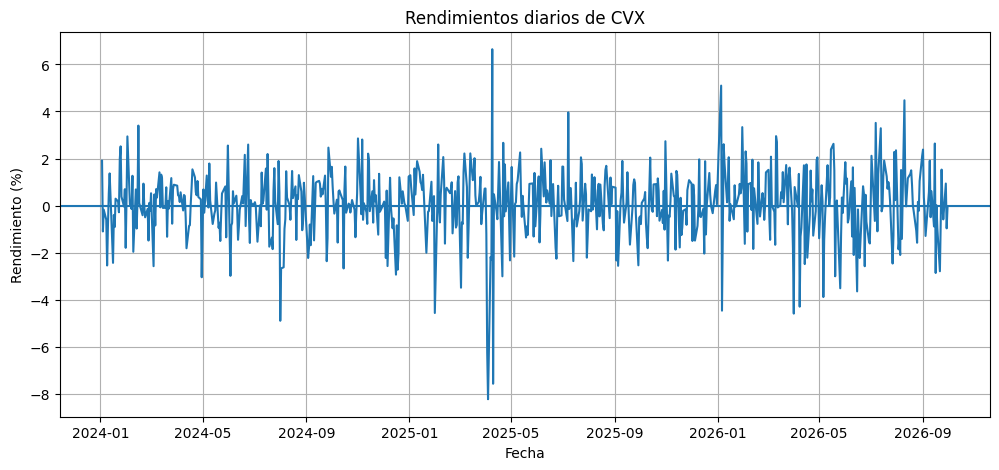

In [ ]:
rendimientos = cierre.pct_change().dropna()

display(rendimientos.describe())

print("Rendimiento promedio (%):",
      rendimientos.mean() * 100)

print("Desviación estándar (%):",
      rendimientos.std() * 100)

plt.figure(figsize=(12, 5))
plt.plot(rendimientos.index, rendimientos * 100)
plt.axhline(0)
plt.title("Rendimientos diarios de CVX")
plt.xlabel("Fecha")
plt.ylabel("Rendimiento (%)")
plt.grid(True)
plt.show()

## 7. Volatilidad móvil
Calcule la volatilidad móvil de 20 días y grafíquela.

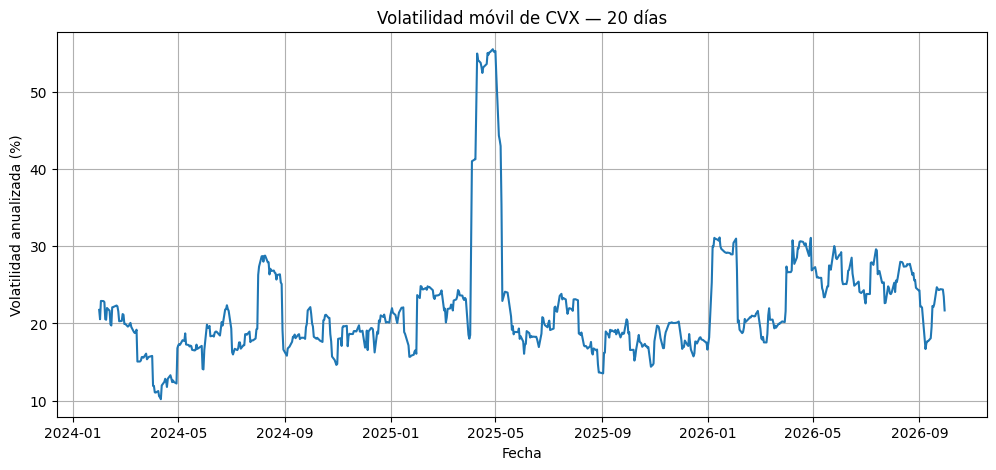

Volatilidad máxima (%): 55.560068509768165
Fecha de volatilidad máxima: 2025-04-28 00:00:00


In [ ]:
volatilidad = rendimientos.rolling(20).std()
volatilidad_anualizada = volatilidad * np.sqrt(252)

plt.figure(figsize=(12, 5))
plt.plot(volatilidad_anualizada.index,
         volatilidad_anualizada * 100)
plt.title("Volatilidad móvil de CVX — 20 días")
plt.xlabel("Fecha")
plt.ylabel("Volatilidad anualizada (%)")
plt.grid(True)
plt.show()

print("Volatilidad máxima (%):",
      volatilidad_anualizada.max() * 100)

print("Fecha de volatilidad máxima:",
      volatilidad_anualizada.idxmax())

**Interpretación:** ¿en qué periodos se concentra la mayor variabilidad?

Análisis de la volatilidad móvil de CVX

La volatilidad móvil de 20 días de la acción de Chevron Corporation (CVX) alcanzó un máximo anualizado de 55,56 % el 28 de abril de 2025. Este resultado indica que, durante la ventana de 20 sesiones bursátiles correspondiente, los rendimientos diarios presentaron una variabilidad elevada en comparación con otros periodos de la serie analizada.

Este comportamiento puede asociarse con una etapa de mayor incertidumbre en el mercado. Sin embargo, para identificar las causas específicas sería necesario contrastar estas fechas con información económica y noticias relacionadas con Chevron y el sector petrolero.

La volatilidad es una medida de riesgo: un valor elevado refleja mayores fluctuaciones de los rendimientos, pero no indica por sí solo si la acción tuvo ganancias o pérdidas. Además, al tratarse de una medida anualizada, el 55,56 % no representa una pérdida ocurrida en un solo día.

## 8. Visualización complementaria
Construya una tercera visualización pertinente (promedio móvil, distribución de rendimientos, comparación mensual u otra) y justifique su elección.


el promedio móvil reduce parte de las fluctuaciones diarias y facilita observar la tendencia reciente.

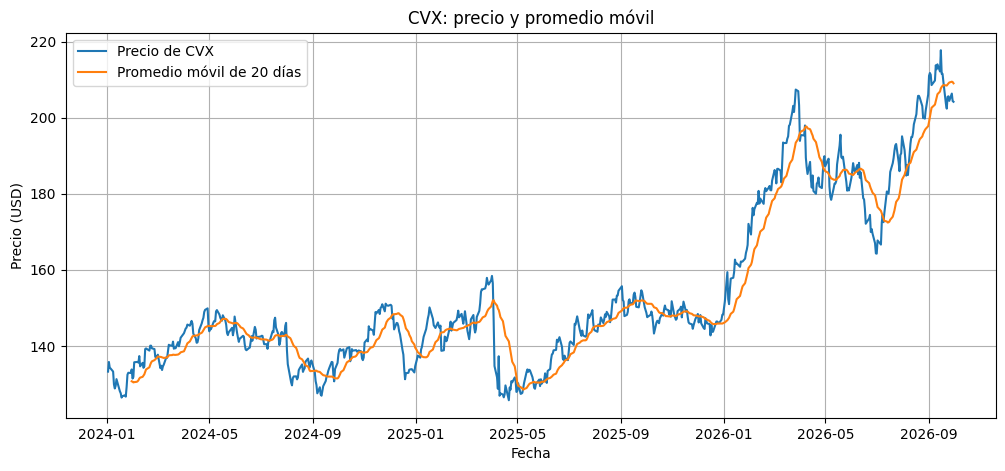

In [ ]:
promedio_movil_20 = cierre.rolling(20).mean()

plt.figure(figsize=(12, 5))
plt.plot(cierre.index, cierre, label="Precio de CVX")
plt.plot(promedio_movil_20.index,
         promedio_movil_20,
         label="Promedio móvil de 20 días")

plt.title("CVX: precio y promedio móvil")
plt.xlabel("Fecha")
plt.ylabel("Precio (USD)")
plt.legend()
plt.grid(True)
plt.show()

## 9. Proyección corta
Plantee una proyección sencilla de corto plazo (por ejemplo, promedio móvil o regresión lineal) y explique sus limitaciones.

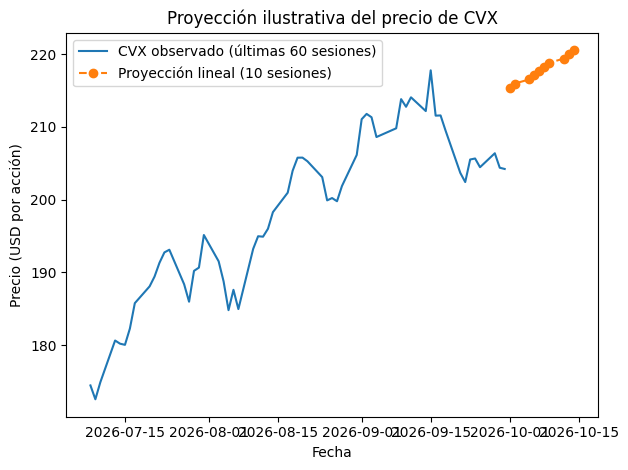

Último cierre observado: $204.21 el 2026-09-30
Precio proyectado para la sesión 10: $220.53
Pendiente estimada: $0.5722 por sesión

Limitaciones: es una extrapolación lineal basada solo en las últimas 60 observaciones. No incorpora noticias, resultados empresariales, precios del petróleo, dividendos futuros ni cambios del mercado; por eso no debe interpretarse como una predicción segura ni como recomendación de inversión.


In [ ]:
# Proyección ilustrativa a 10 sesiones bursátiles mediante regresión lineal
# sobre las últimas 60 observaciones disponibles.
ventana = cierre.tail(60)
x = np.arange(len(ventana))
pendiente, intercepto = np.polyfit(x, ventana.values, 1)

horizonte = 10
x_futuro = np.arange(len(ventana), len(ventana) + horizonte)
proyeccion = pendiente * x_futuro + intercepto

# Fechas futuras aproximadas de días hábiles (no incorpora festivos bursátiles).
fechas_futuras = pd.bdate_range(
    start=cierre.index[-1] + pd.Timedelta(days=1),
    periods=horizonte
)
serie_proyectada = pd.Series(proyeccion, index=fechas_futuras, name="Proyección lineal")

plt.figure()
plt.plot(ventana.index, ventana.values, label="CVX observado (últimas 60 sesiones)")
plt.plot(serie_proyectada.index, serie_proyectada.values,
         marker="o", linestyle="--", label="Proyección lineal (10 sesiones)")
plt.title("Proyección ilustrativa del precio de CVX")
plt.xlabel("Fecha")
plt.ylabel("Precio (USD por acción)")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Último cierre observado: ${cierre.iloc[-1]:.2f} el {cierre.index[-1].date()}")
print(f"Precio proyectado para la sesión {horizonte}: ${serie_proyectada.iloc[-1]:.2f}")
print(f"Pendiente estimada: ${pendiente:.4f} por sesión")

print("\nLimitaciones: es una extrapolación lineal basada solo en las últimas 60 observaciones. No incorpora noticias, resultados empresariales, precios del petróleo, dividendos futuros ni cambios del mercado; por eso no debe interpretarse como una predicción segura ni como recomendación de inversión.")

## 10. Conclusión financiera
Redacte tres conclusiones concretas sobre comportamiento, riesgo y límites del análisis.

1.
2.
3.


1. Comportamiento del precio: Durante el periodo analizado, la acción de Chevron Corporation (CVX) mostró una tendencia general ascendente, especialmente durante 2026, aunque presentó varias fluctuaciones y correcciones. El precio mínimo registrado fue de US$125,71 el 21 de abril de 2025, mientras que el máximo fue de US$217,77 el 15 de septiembre de 2026. La gráfica del precio y el promedio móvil de 20 días permite observar estos cambios de tendencia. En general, el precio pasó de valores cercanos a US$135 al inicio de 2024 a valores superiores a US$200 hacia el final del periodo analizado.

2. Rendimiento y riesgo: El rendimiento diario promedio fue de aproximadamente 0,0726 %, lo que indica que los rendimientos diarios fueron ligeramente positivos en promedio. La desviación estándar diaria fue de 1,4474 %, lo que evidencia variaciones en los rendimientos. Además, la volatilidad móvil anualizada de 20 sesiones alcanzó un máximo de 55,56 % el 28 de abril de 2025, reflejando un periodo de mayor variabilidad e incertidumbre. Por lo tanto, aunque la acción mostró un comportamiento general ascendente, también estuvo expuesta a fluctuaciones importantes del mercado.

3. Proyección y limitaciones: La proyección lineal basada en las últimas 60 observaciones estimó un precio de US$220,53 para la sesión número 10, tomando como último cierre observado US$204,21 el 30 de septiembre de 2026. La pendiente estimada fue de US$0,5722 por sesión, lo que indica una tendencia positiva dentro del modelo. Sin embargo, esta proyección no garantiza que el precio alcance dicho valor, ya que no incorpora noticias, resultados empresariales, cambios en los precios internacionales del petróleo, dividendos futuros ni otras condiciones del mercado. Por esta razón, la proyección debe interpretarse como una estimación matemática y no como una predicción segura ni una recomendación de inversión.

## 11. Video de sustentación
Pegue el enlace de su video individual (máximo 5 minutos). En el video explique su activo, sus gráficos y sus conclusiones.

https://drive.google.com/file/d/1b686nfdiTBFxMbaDIuQHHKS2xAjk6xS8/view?usp=drive_link